# Lumina & Co — nettoyage et exploration des données

Jour 1. Lumina & Co est une marque française de cosmétiques vendue en direct au
consommateur. La croissance était forte jusqu'en 2024, elle stagne depuis. Le CMO
demande si envoyer les mêmes emails à toute la base est un problème.

Avant de pouvoir répondre, il faut savoir sur quelles données on travaille. Ce
notebook fait l'inventaire, traite les anomalies, puis explore. Le fichier
nettoyé produit à la fin servira à la segmentation RFM du Jour 2.

## 1. Chargement et diagnostic

On pourrait démarrer directement par le nettoyage, mais ce serait une erreur.
Tant qu'on n'a pas mesuré ce qui manque et ce qui est incohérent, on ne sait pas
si une décision de traitement porte sur 200 lignes ou sur un quart du fichier. Et
ce n'est pas la même conversation avec le CMO.

Cette section ne modifie rien. Elle répond à quatre questions : quel volume et
quelle période, quelles colonnes sont incomplètes, les types sont-ils ceux qu'on
attend, y a-t-il des doublons. Elle se termine par cinq observations à retenir.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

DOSSIER_DONNEES = Path.cwd().parent / "data"
DOSSIER_BRUT = DOSSIER_DONNEES / "raw"
DOSSIER_TRAITE = DOSSIER_DONNEES / "processed"

Le chargement mérite deux précisions. `parse_dates` convertit les colonnes de
dates au moment de la lecture plutôt qu'après coup : sans ça, pandas les traite
comme du texte et toute comparaison chronologique devient fausse.
`low_memory=False` force pandas à lire le fichier d'un bloc avant de deviner les
types ; par défaut il procède par morceaux et peut attribuer deux types
différents à la même colonne sur un fichier d'un million et demi de lignes.

In [2]:
df_customers = pd.read_csv(
    DOSSIER_BRUT / "customers.csv",
    parse_dates=["first_purchase", "last_purchase"],
)

df_transactions = pd.read_csv(
    DOSSIER_BRUT / "transactions.csv",
    parse_dates=["invoice_date"],
    low_memory=False,
)

df_customers.head()

,customer_id,country,first_purchase,last_purchase,n_orders,total_spent,avg_basket,recency_days,tenure_days,declared_preference,age_bracket,life_stage,urban_density
0,56396,France,2026-05-18 00:00:00,2026-06-11 00:00:00,1,757.68,757.6800,19,24,NaN,NaN,NaN,Zone urbaine dense
1,14297,France,2025-09-28 19:41:00,2026-06-12 20:16:00,4,2325.35,581.3375,17,274,NaN,NaN,NaN,NaN
2,34160,France,2024-03-25 00:00:00,2025-06-03 00:00:00,1,519.12,519.1200,392,435,Peau sèche,45-54 ans,NaN,NaN
3,61352,France,2023-06-21 00:00:00,2025-03-02 00:00:00,4,6394.33,1598.5800,485,620,Peau sèche,35-44 ans,Jeune actif en solo,NaN
4,20612,France,2025-09-19 00:00:00,2026-06-17 00:00:00,9,5918.34,657.5900,13,271,NaN,NaN,NaN,NaN


In [3]:
df_transactions.head()

,invoice_id,customer_id,product_code,product_name,category,quantity,unit_price,invoice_date,country
0,509453,13381.0,82583,Savon Surgras Lavande,Corps,3,7.72,2024-12-12 20:59:00,France
1,558926,17469.0,23201,Lait Corps Amande Douce,Corps,1,18.21,2026-01-23 21:31:00,France
2,567853,15484.0,23289,Savon Surgras Lavande,Corps,1,7.53,2026-04-13 00:41:00,France
3,549949,13208.0,22289,Huile Démaquillante Camélia,Visage,1,22.84,2025-11-02 00:07:00,France
4,505081,16742.0,22607,Coffret Découverte Rituel Slow Beauty,Coffret,1,47.12,2024-11-08 20:59:00,France


Deux tables au grain différent : un client par ligne dans la première, un produit
facturé par ligne dans la seconde. Une facture s'étale donc sur plusieurs lignes
de `transactions`.

`customers.csv` contient déjà des métriques agrégées (`n_orders`, `total_spent`,
`avg_basket`, `recency_days`). Il faudra vérifier plus tard si elles sont
cohérentes avec ce qu'on recalcule depuis les transactions — rien ne garantit
qu'elles aient été produites après les mêmes filtres.

In [4]:
print("customers   :", f"{len(df_customers):>9,}".replace(",", " "), "lignes,",
      df_customers["customer_id"].nunique(), "clients distincts")
print("transactions:",
      f"{len(df_transactions):>9,}".replace(",", " "), "lignes,",
      df_transactions["invoice_id"].nunique(), "factures distinctes,",
      df_transactions["customer_id"].nunique(), "clients distincts")

date_min = df_transactions["invoice_date"].min()
date_max = df_transactions["invoice_date"].max()
duree_mois = ((date_max.year - date_min.year) * 12
              + date_max.month - date_min.month)
print(f"\npériode couverte : {date_min:%d/%m/%Y} -> {date_max:%d/%m/%Y} "
      f"({duree_mois} mois)")

customers   :    50 295 lignes, 50295 clients distincts
transactions: 1 613 433 lignes, 247690 factures distinctes, 49402 clients distincts

période couverte : 07/01/2022 -> 30/06/2026 (53 mois)


Un peu plus de quatre ans et demi d'historique, ce qui couvre bien la période de
croissance puis de stagnation évoquée par le CMO. On pourra donc regarder si le
ralentissement se voit dans le CA mensuel.

Premier écart à noter : le nombre de clients distincts dans `transactions` n'est
pas le même que dans `customers`. On y revient plus bas.

In [5]:
def resumer_valeurs_manquantes(df, nom_table):
    """Retourne le nombre et la part de valeurs manquantes par colonne.

    Seules les colonnes réellement incomplètes sont conservées, triées de la
    plus lacunaire à la moins lacunaire.
    """
    nb_manquants = df.isna().sum()
    resume = pd.DataFrame({
        "table": nom_table,
        "nb_manquants": nb_manquants,
        "part_manquants_pct": (nb_manquants / len(df) * 100).round(2),
    })
    return resume[resume["nb_manquants"] > 0].sort_values(
        "nb_manquants", ascending=False
    )


pd.concat([
    resumer_valeurs_manquantes(df_customers, "customers"),
    resumer_valeurs_manquantes(df_transactions, "transactions"),
])

,table,nb_manquants,part_manquants_pct
urban_density,customers,40332,80.19
life_stage,customers,38986,77.51
declared_preference,customers,31108,61.85
age_bracket,customers,28821,57.30
customer_id,transactions,367328,22.77
product_name,transactions,2241,0.14


Deux problèmes de nature très différente, qu'il ne faut surtout pas traiter de la
même façon.

Dans `transactions`, `customer_id` est manquant sur près d'une ligne sur quatre.
Ce n'est pas une colonne annexe : c'est la clé qui relie un achat à une personne.
Sans elle, ces lignes comptent dans le chiffre d'affaires mais sont invisibles
pour toute analyse client. Concrètement, si on segmente demain sans y toucher, on
segmente sur 77 % des ventes en croyant en couvrir la totalité. Le traitement se
décide à l'étape 2.

Dans `customers`, ce sont les quatre colonnes déclaratives qui sont creuses, entre
57 % et 80 % de vide. C'est attendu et on y revient à l'étape 3 : ces champs ne
sont remplis que si le client a bien voulu répondre.

`product_name` manque sur 0,14 % des lignes, ce qui est marginal et ne bloque
aucun calcul puisque `product_code` et `category`, eux, sont toujours présents.

In [6]:
pd.DataFrame({
    "customers": df_customers.dtypes.astype(str),
    "transactions": df_transactions.dtypes.astype(str),
})

,customers,transactions
age_bracket,str,NaN
avg_basket,float64,NaN
category,NaN,str
country,str,str
customer_id,int64,float64
declared_preference,str,NaN
first_purchase,datetime64[us],NaN
invoice_date,NaN,datetime64[us]
invoice_id,NaN,str
last_purchase,datetime64[us],NaN


Deux types ne sont pas ceux qu'on attendrait, et les deux disent quelque chose.

`customer_id` est un `float64` dans `transactions` alors que c'est un entier dans
`customers`. Ce n'est pas une erreur de pandas : un entier ne peut pas porter de
valeur manquante, donc dès qu'une colonne d'entiers contient un vide, pandas la
bascule en décimal. Le type nous signale le problème repéré juste au-dessus. Il
faudra réaligner les deux colonnes avant toute jointure, sinon elle ne
correspondra sur rien.

`invoice_id` est du texte et pas un nombre. Il y a donc des numéros de facture
non numériques. À vérifier tout de suite, parce que ce genre de convention cache
souvent un type de document particulier.

In [7]:
factures_non_numeriques = df_transactions.loc[
    ~df_transactions["invoice_id"].str.fullmatch(r"\d+"), "invoice_id"
]

print("lignes concernées   :", len(factures_non_numeriques))
print("factures distinctes :", factures_non_numeriques.nunique())
print("exemples            :", factures_non_numeriques.unique()[:5].tolist())

prefixes = factures_non_numeriques.str.extract(r"^(\D+)")[0]
print("\nrépartition par préfixe :")
print(pd.DataFrame({
    "nb_lignes": prefixes.value_counts(),
    "nb_factures": factures_non_numeriques.groupby(prefixes).nunique(),
}))

lignes concernées   : 19500
factures distinctes : 8298
exemples            : ['C506602', 'C510213', 'C518342', 'C536080', 'C557387']

répartition par préfixe :
   nb_lignes  nb_factures
0                        
A          6            6
C      19494         8292


Presque toutes commencent par `C` : c'est la convention classique des avoirs, une
facture d'annulation émise après un retour. Ce sont de vraies opérations
comptables, pas des erreurs de saisie, et elles expliqueront une partie des
quantités négatives qu'on traitera à l'étape 2.

Six lignes seulement portent un préfixe `A`, et je n'ai pas d'explication solide
à ce stade. Six lignes sur un million six cent mille, je note et je passe — si ça
comptait vraiment, il faudrait poser la question au service comptable plutôt que
d'inventer une interprétation.

In [8]:
nb_doublons_stricts = df_transactions.duplicated().sum()
nb_doublons_cle = df_transactions.duplicated(
    subset=["invoice_id", "product_code"]
).sum()

print("lignes strictement identiques      :", nb_doublons_stricts)
print("couples (facture, produit) répétés :", nb_doublons_cle)
print("doublons dans customers            :",
      df_customers["customer_id"].duplicated().sum())

lignes strictement identiques      : 445
couples (facture, produit) répétés : 47890
doublons dans customers            : 0


`customers` est propre sur ce point : un identifiant, un client.

Dans `transactions`, les 445 lignes strictement identiques sont trop peu
nombreuses pour peser sur les agrégats, mais leur existence dit que l'export n'a
pas de garantie d'unicité.

Le second chiffre est plus intéressant : il y a beaucoup plus de couples
(facture, produit) répétés que de lignes identiques. Un même produit apparaît
donc plusieurs fois sur une même facture avec des quantités ou des prix
différents. Ce n'est pas forcément anormal — remise appliquée sur une partie de
la quantité, article ajouté en deux fois — mais cela veut dire que
`invoice_id` + `product_code` n'est pas une clé primaire, et qu'on ne peut pas
dédoublonner là-dessus.

In [9]:
identifiants_customers = set(df_customers["customer_id"])
identifiants_transactions = set(
    df_transactions["customer_id"].dropna().astype("int64")
)

clients_absents_du_referentiel = (
    identifiants_transactions - identifiants_customers
)
clients_sans_transaction = identifiants_customers - identifiants_transactions

print("clients présents dans transactions mais absents de customers :",
      len(clients_absents_du_referentiel))
print("clients présents dans customers mais sans aucune transaction :",
      len(clients_sans_transaction))

clients présents dans transactions mais absents de customers : 90
clients présents dans customers mais sans aucune transaction : 983


Ce contrôle n'était pas explicitement demandé, mais il conditionne tout le Jour 2 :
si les deux tables ne se recouvrent pas, la segmentation portera sur une base
différente de celle qu'on croit cibler.

Le résultat est plutôt rassurant. 90 clients apparaissent dans les ventes sans
exister au référentiel : quelques dizaines de comptes créés après l'export, ou
supprimés entre-temps. À l'échelle de 50 000 clients, c'est négligeable.

Les 983 clients sans aucune transaction sont plus curieux, puisque `customers`
leur attribue quand même un `n_orders` et un `total_spent`. Deux explications
tiennent : soit leurs achats font partie des lignes sans `customer_id`, soit les
métriques agrégées ont été calculées à une autre date que l'extraction des
transactions. Je vérifierai à l'étape 2 avant de décider s'il faut recalculer ces
métriques ou faire confiance au fichier.

Dernier repérage avant de clore le diagnostic. Trois choses sautent aux yeux à la
lecture du fichier et méritent d'être chiffrées tout de suite, parce qu'elles
pèsent sur ce qu'on pourra dire au CMO : la concentration géographique, les
quantités négatives, et la présence de lignes qui ne sont pas des produits. Le
traitement viendra à l'étape 2, ici on ne fait que mesurer.

In [10]:
repartition_pays = df_customers["country"].value_counts()
part_pays = (repartition_pays / len(df_customers) * 100).round(1)
print("clients par pays (top 5) :")
tableau_pays = pd.DataFrame({"nb_clients": repartition_pays,
                             "part_pct": part_pays})
print(tableau_pays.head())

nb_quantites_negatives = (df_transactions["quantity"] < 0).sum()
nb_prix_nuls = (df_transactions["unit_price"] == 0).sum()
nb_prix_negatifs = (df_transactions["unit_price"] < 0).sum()
print(f"\nquantités négatives : {nb_quantites_negatives}")
print(f"prix unitaires nuls : {nb_prix_nuls}")
print(f"prix unitaires négatifs : {nb_prix_negatifs}")

print("\nlignes par catégorie :")
print(df_transactions["category"].value_counts())

lignes_de_frais = df_transactions["category"] == "Frais"
print("\nlibellés de la catégorie Frais :")
print(df_transactions.loc[lignes_de_frais, "product_name"].value_counts())

clients par pays (top 5) :
                nb_clients  part_pct
country                             
France               45904      91.3
Germany                918       1.8
United Kingdom         760       1.5
Spain                  291       0.6
Portugal               211       0.4

quantités négatives : 34691
prix unitaires nuls : 10897
prix unitaires négatifs : 177

lignes par catégorie :
category
Visage        456310
Corps         381933
Cheveux       231433
Accessoire    218173
Bain          189605
Coffret       128514
Frais           7465
Name: count, dtype: int64

libellés de la catégorie Frais :
product_name
Frais divers          3174
Frais de port         2122
Ajustement manuel     1426
Frais de carte         282
Remise commerciale     177
Échantillon            104
Frais bancaires        102
Frais marketplace       43
Emballage               19
Don caritatif           16
Name: count, dtype: int64


La France représente 91 % des clients. Les autres pays ne sont pas absents, mais
avec 918 clients allemands et 760 britanniques, aucun ne permet une analyse
séparée solide. C'est une contrainte structurelle de la base, pas un défaut de
qualité, et elle se répercutera sur tout ce qu'on modélisera ensuite.

34 691 quantités négatives pour 19 494 lignes d'avoir : les retours n'expliquent
qu'un peu plus de la moitié. Il reste une seconde population à identifier.

La catégorie `Frais` regroupe bien ce que son nom annonce — frais de port,
ajustements manuels, remises, frais bancaires, commissions marketplace,
échantillons. 7 465 lignes, soit moins de 0,5 % du fichier, mais elles portent des
montants qui n'ont rien à voir avec une vente de produit.

### Data quality report — cinq observations avant nettoyage

Un biais qu'on ne documente pas devient invisible : personne ne peut plus le
corriger ni en tenir compte. Voici donc ce que je retiens de l'état brut des
données, avant d'y avoir touché.

**1. Un quart des ventes n'est rattaché à aucun client.** 367 328 lignes de
transactions sur 1 613 433 n'ont pas de `customer_id`. Le chiffre d'affaires les
inclut, l'analyse client non. Toute lecture par client porte donc sur une partie
seulement de l'activité, et il faudra le dire au CMO plutôt que de présenter les
segments comme exhaustifs.

**2. La base est française à 91 %.** 45 904 clients sur 50 295 sont en France.
Les autres pays existent mais sont trop peu nombreux pour être analysés
séparément de façon fiable. Conséquence directe pour le Jour 2 : les segments
qu'on produira décriront le comportement du client français, et les appliquer
tels quels à l'Allemagne ou au Royaume-Uni serait une extrapolation. C'est une
limite à porter jusqu'à la présentation finale.

**3. Les données déclaratives sont majoritairement vides.** `urban_density` est
remplie pour 20 % des clients, `life_stage` pour 22 %, `age_bracket` pour 43 %,
`declared_preference` pour 38 %. Une personnalisation qui reposerait sur ces
champs ne toucherait qu'une minorité de la base.

**4. Les quantités négatives et les avoirs sont présents dans le fichier.**
8 292 factures d'avoir, soit 19 494 lignes, contre 34 691 lignes à quantité
négative. Les retours n'expliquent donc qu'un peu plus de la moitié des négatifs,
il reste une autre source à identifier. Non traitées, ces lignes fausseront tout
calcul de chiffre d'affaires cumulé par client.

**5. Le fichier mélange des produits et des lignes qui n'en sont pas.** Une
catégorie `Frais` regroupe frais de port, ajustements manuels, frais bancaires,
commissions marketplace. Les compter comme des ventes gonflerait le panier moyen
et polluerait l'analyse des catégories produit.

Ces cinq points sont ceux qui changent quelque chose à une décision marketing.
Les doublons stricts et les 90 clients orphelins sont réels mais trop marginaux
pour figurer ici.

## 2. Détection et traitement des anomalies

Le diagnostic a laissé quatre questions ouvertes : que représentent les lignes
sans client, d'où viennent les quantités négatives, un prix à zéro est-il une
erreur, et comment repérer les lignes qui ne sont pas des produits.

Sur chacune il y a rarement une seule bonne réponse. Je pose les options, je
tranche, et j'écris pourquoi. La règle que je m'impose : ne jamais supprimer une
ligne quand un indicateur booléen suffit à l'écarter au moment de l'analyse. Une
suppression est définitive, un flag se discute.

### 2.1 Deux sources d'export dans un même fichier

En cherchant l'origine des quantités négatives, je suis tombé sur autre chose. Le
numéro de facture n'est pas une simple séquence : au-delà de 600 000, les
factures n'ont plus la même tête. Autant le vérifier avant d'aller plus loin,
parce que si le fichier réunit deux exports différents, chaque décision qui suit
doit en tenir compte.

In [11]:
SEUIL_NUMERO_FACTURE = 600_000  # rupture observée dans la numérotation

df_transactions["numero_facture"] = pd.to_numeric(
    df_transactions["invoice_id"].str.extract(r"(\d+)")[0]
)
df_transactions["source_export"] = np.where(
    df_transactions["numero_facture"] >= SEUIL_NUMERO_FACTURE, "B", "A"
)

horodatage_a_minuit = (
    (df_transactions["invoice_date"].dt.hour == 0)
    & (df_transactions["invoice_date"].dt.minute == 0)
)

comparaison_sources = df_transactions.groupby("source_export").agg(
    nb_lignes=("invoice_id", "size"),
    nb_clients=("customer_id", "nunique"),
    date_min=("invoice_date", "min"),
    date_max=("invoice_date", "max"),
)
source_de_chaque_ligne = df_transactions["source_export"]
comparaison_sources["part_horodatage_a_minuit"] = (
    horodatage_a_minuit.groupby(source_de_chaque_ligne).mean().round(3)
)
comparaison_sources["nb_avoirs"] = (
    df_transactions["invoice_id"].str.startswith("C")
    .groupby(source_de_chaque_ligne).sum()
)
comparaison_sources

,nb_lignes,nb_clients,date_min,date_max,part_horodatage_a_minuit,nb_avoirs
source_export,,,,,,
A,1120679,7399,2024-03-02,2026-06-30,0.05,19494
B,492754,42004,2022-01-07,2026-06-30,1.00,0


In [12]:
est_source_a = df_transactions["source_export"] == "A"
est_source_b = df_transactions["source_export"] == "B"

clients_source_a = set(
    df_transactions.loc[est_source_a, "customer_id"].dropna()
)
clients_source_b = set(
    df_transactions.loc[est_source_b, "customer_id"].dropna()
)

print("clients source A :", len(clients_source_a))
print("clients source B :", len(clients_source_b))
print("clients communs  :", len(clients_source_a & clients_source_b))

clients source A : 7399
clients source B : 42004
clients communs  : 1


Un seul client commun sur 49 402. Ce ne sont pas deux périodes d'une même base,
ce sont deux populations distinctes empilées dans un même fichier, et elles ne se
comportent pas pareil :

- la source A porte tous les avoirs, garde l'heure exacte des commandes, et ne
  couvre que 2024-2026 ;
- la source B n'a aucun avoir, ses dates sont tronquées à la journée, et elle
  remonte jusqu'à 2022.

Deux options se présentaient. Ne garder qu'une source, ce qui donnerait une base
homogène mais amputerait soit 42 000 clients soit quatre ans d'historique. Ou
tout garder en marquant l'origine de chaque ligne. Je retiens la seconde : le CMO
pilote une seule marque, pas deux, et lui rendre une analyse sur un tiers de sa
base au nom de la propreté méthodologique serait un mauvais service.

En revanche la colonne `source_export` reste dans le dataset. Au Jour 2, si un
segment RFM se révèle composé à 95 % d'une seule source, ce sera un artefact
d'export avant d'être un comportement client, et il faudra pouvoir le vérifier.

### 2.2 Les `customer_id` manquants

367 328 lignes, presque un quart du fichier. La lecture habituelle, c'est l'achat
sans création de compte : le client passe en invité, on encaisse la vente sans
savoir qui il est.

Si c'était vrai, une facture serait soit entièrement anonyme soit entièrement
identifiée. Vérifions.

In [13]:
identifiants_par_facture = df_transactions.groupby("invoice_id")["customer_id"]
factures_mixtes = identifiants_par_facture.apply(
    lambda ids: ids.isna().any() and ids.notna().any()
)

lignes_sans_client = df_transactions["customer_id"].isna()
nb_factures_concernees = (
    df_transactions.loc[lignes_sans_client, "invoice_id"].nunique()
)

print("factures avec au moins une ligne sans client :", nb_factures_concernees)
print("dont factures mixtes (lignes avec ET sans)   :", factures_mixtes.sum())
print("factures portant plus d'un client distinct   :",
      (identifiants_par_facture.nunique() > 1).sum())

factures avec au moins une ligne sans client : 102713
dont factures mixtes (lignes avec ET sans)   : 80164
factures portant plus d'un client distinct   : 0


80 164 factures sur 102 713 sont mixtes. La même facture porte donc à la fois des
lignes rattachées et des lignes vides : ce n'est pas un achat en invité, c'est une
perte d'information au niveau de la ligne, probablement à l'export.

Et surtout, aucune facture ne porte deux clients différents. On peut donc
récupérer l'identifiant manquant en le reprenant sur les autres lignes de la même
facture, sans risque d'attribuer une vente au mauvais client.

In [14]:
client_par_facture = (
    df_transactions.dropna(subset=["customer_id"])
    .groupby("invoice_id")["customer_id"]
    .first()
)

df_transactions["client_rattache"] = df_transactions["customer_id"].fillna(
    df_transactions["invoice_id"].map(client_par_facture)
)

nb_lignes_recuperees = (
    df_transactions["customer_id"].isna()
    & df_transactions["client_rattache"].notna()
).sum()
nb_lignes_anonymes = df_transactions["client_rattache"].isna().sum()

print("lignes récupérées par propagation :", nb_lignes_recuperees)
print("lignes restant anonymes           :", nb_lignes_anonymes)
print("taux de rattachement : %.1f %% -> %.1f %%" % (
    df_transactions["customer_id"].notna().mean() * 100,
    df_transactions["client_rattache"].notna().mean() * 100,
))

lignes récupérées par propagation : 107231
lignes restant anonymes           : 260097
taux de rattachement : 77.2 % -> 83.9 %


Le taux de rattachement passe de 77,2 % à 83,9 %. 107 231 lignes de vente
redeviennent exploitables pour l'analyse client, sans aucune hypothèse : elles
étaient déjà sur une facture nominative.

Restent 260 097 lignes sur des factures entièrement anonymes. Trois traitements
possibles : les supprimer, les conserver telles quelles, ou leur inventer un
identifiant.

L'imputation est à écarter d'emblée. Fabriquer des identifiants créerait de faux
clients qui viendraient gonfler les effectifs de segments au Jour 2, et personne
ne pourrait démêler les vrais des faux ensuite.

Entre supprimer et conserver, je conserve, avec un indicateur `client_identifie`.
Ces lignes sont de vraies ventes : les jeter fausserait le chiffre d'affaires et
la saisonnalité, qui n'ont pas besoin du client pour être calculés. Les analyses
qui exigent un client filtreront sur le flag. Le coût de ce choix est qu'il faut
penser à filtrer, et je l'assume : l'inverse — supprimer d'abord — fait perdre de
l'information sans possibilité de retour.

### 2.3 Les quantités négatives

L'étape 1 avait laissé un trou : 34 691 lignes négatives pour 19 494 lignes
d'avoir seulement. Maintenant qu'on sait que le fichier réunit deux sources, la
question devient : est-ce que les négatifs restants viennent de la source qui
n'utilise pas d'avoirs ?

In [15]:
df_transactions["est_avoir"] = (
    df_transactions["invoice_id"].str.startswith("C")
)
lignes_negatives = df_transactions["quantity"] < 0

print(pd.crosstab(
    df_transactions.loc[lignes_negatives, "source_export"],
    df_transactions.loc[lignes_negatives, "est_avoir"],
    rownames=["source"], colnames=["facture d'avoir"], margins=True,
))

facture d'avoir  False   True    All
source                              
A                 4593  19493  24086
B                10605      0  10605
All              15198  19493  34691


La source B ne produit aucun avoir : ses 10 605 retours sont écrits directement en
quantité négative sur la facture d'origine. La source A utilise les deux
conventions, majoritairement l'avoir.

Ce sont donc les mêmes événements métier — des retours produits — encodés de deux
façons. Il n'y a pas d'erreur de saisie à corriger, il y a deux façons différentes
d'écrire la même chose. Le bon repère n'est ni le préfixe `C` ni la source, c'est le
signe de la quantité.

In [16]:
df_transactions["line_total"] = (
    df_transactions["quantity"] * df_transactions["unit_price"]
)
df_transactions["est_retour"] = df_transactions["quantity"] < 0

ca_brut = df_transactions["line_total"].sum()
ca_retours = df_transactions.loc[df_transactions["est_retour"],
                                 "line_total"].sum()
part_retours = -ca_retours / (ca_brut - ca_retours) * 100

print("CA hors retours : %12.0f €" % (ca_brut - ca_retours))
print("retours         : %12.0f €" % ca_retours)
print("CA net          : %12.0f €" % ca_brut)
print("les retours représentent %.1f %% du CA brut" % part_retours)

CA hors retours :     51599656 €
retours         :      -987459 €
CA net          :     50612197 €
les retours représentent 1.9 % du CA brut


Un peu moins de deux pour cent du chiffre d'affaires brut. Faible en masse, mais
l'impact sur les agrégations futures n'est pas proportionnel : le RFM du Jour 2
se calcule client par client, et un client qui commande beaucoup puis retourne tout n'a pas la même
valeur qu'un client qui garde ses achats. Supprimer les lignes négatives
reviendrait à ne voir que la moitié de sa relation à la marque.

Je conserve donc, avec le flag `est_retour`. La conséquence pratique, à ne pas
oublier demain : le montant dépensé par client doit être une somme signée, pas
une somme de valeurs absolues.

### 2.4 Les prix à zéro

10 897 lignes. Anomalie de saisie ou geste commercial ? Le test qui départage :
si ces produits sont vendus à un prix normal ailleurs dans le fichier, alors le
zéro est une décision, pas une erreur de catalogue.

In [17]:
lignes_gratuites = df_transactions["unit_price"] == 0

lignes_payantes = df_transactions["unit_price"] > 0
codes_a_zero = set(df_transactions.loc[lignes_gratuites, "product_code"])
codes_payants = set(df_transactions.loc[lignes_payantes, "product_code"])

print("codes produits concernés            :", len(codes_a_zero))
print("dont vendus à prix positif ailleurs :",
      len(codes_a_zero & codes_payants))
print("part de lignes en quantité négative : %.1f %%"
      % (df_transactions.loc[lignes_gratuites, "quantity"].lt(0).mean() * 100))
print("\nlibellés les plus fréquents :")
print(df_transactions.loc[lignes_gratuites, "product_name"]
      .value_counts().head(5))

lignes_prix_negatif = df_transactions["unit_price"] < 0
print("\nprix négatifs :", lignes_prix_negatif.sum(), "lignes")
print(df_transactions.loc[lignes_prix_negatif, "product_name"].value_counts())

codes produits concernés            : 3693
dont vendus à prix positif ailleurs : 3343
part de lignes en quantité négative : 38.4 %

libellés les plus fréquents :
product_name
Ajustement manuel                 1426
Contour des Yeux Concombre         434
Brosse Corps Fibres Naturelles     411
Trousse Voyage Rechargeable        408
Savon Surgras Lavande              408
Name: count, dtype: int64

prix négatifs : 177 lignes
product_name
Remise commerciale    177
Name: count, dtype: int64


Neuf codes sur dix sont vendus payants ailleurs. Ce sont donc de vrais produits
donnés : échantillons, cadeaux d'anniversaire, gestes commerciaux après un
incident. Le cas métier est légitime, il ne faut pas y toucher. S'y ajoutent
1 426 lignes « Ajustement manuel », qui relèvent de la comptabilité et pas de la
vente.

Un point m'a fait hésiter : 38 % de ces lignes ont aussi une quantité négative.
Un produit gratuit repris à zéro euro n'a aucun effet sur le CA. C'est de la
gestion de stock qui s'est retrouvée dans le fichier de ventes.

Je conserve tout et je pose `ligne_gratuite`. La raison est concrète : ces lignes
ne doivent pas entrer dans un panier moyen, où elles le tireraient vers le bas
artificiellement, mais elles doivent rester dans le comptage des volumes — un
client qui reçoit trois échantillons est un client actif.

Les 177 prix négatifs sont tous des « Remise commerciale », sur avoir. Une remise
inscrite en montant négatif est cohérente ; je les traite avec les lignes qui ne
sont pas des produits, juste en dessous.

### 2.5 Les lignes qui ne sont pas des produits

C'est le point où j'ai le plus hésité, parce que le fichier donne deux signaux et
qu'ils ne disent pas la même chose.

In [18]:
codes_sans_chiffre = ~df_transactions["product_code"].str.contains(
    r"\d", regex=True
)

print("lignes dont le code ne contient aucun chiffre :",
      codes_sans_chiffre.sum())
print("codes distincts :",
      sorted(df_transactions.loc[codes_sans_chiffre, "product_code"].unique()))

categorie_frais = df_transactions["category"] == "Frais"

print("\nlignes en catégorie Frais :", categorie_frais.sum())
print("libellés :")
print(df_transactions.loc[categorie_frais, "product_name"].value_counts())

print("\nles deux critères ne se recouvrent pas :")
print("  code sans chiffre mais catégorie produit :",
      (codes_sans_chiffre & ~categorie_frais).sum())
print("  catégorie Frais mais code numérique      :",
      (categorie_frais & ~codes_sans_chiffre).sum())

lignes_frais_de_port = df_transactions["product_code"].str.upper() == "POST"
print("\nexemple, le code POST (frais de port) :")
print(df_transactions.loc[lignes_frais_de_port, "category"].value_counts())

lignes dont le code ne contient aucun chiffre : 6513
codes distincts : ['ADJUST', 'AMAZONFEE', 'B', 'BANK CHARGES', 'CRUK', 'D', 'DCGSLBOY', 'DCGSLGIRL', 'DCGSSBOY', 'DCGSSGIRL', 'DOT', 'GIFT', 'M', 'PADS', 'POST', 'S', 'm']

lignes en catégorie Frais : 7465
libellés :
product_name
Frais divers          3174
Frais de port         2122
Ajustement manuel     1426
Frais de carte         282
Remise commerciale     177
Échantillon            104
Frais bancaires        102
Frais marketplace       43
Emballage               19
Don caritatif           16
Name: count, dtype: int64

les deux critères ne se recouvrent pas :
  code sans chiffre mais catégorie produit : 934
  catégorie Frais mais code numérique      : 1886

exemple, le code POST (frais de port) :
category
Frais         2122
Corps           12
Visage          12
Bain             8
Coffret          8
Accessoire       7
Cheveux          7
Name: count, dtype: int64


Le premier signal est la catégorie `Frais`, et son contenu est sans ambiguïté :
frais de port, frais bancaires, commissions marketplace, ajustements manuels,
remises, échantillons, dons. 7 465 lignes.

Le second est le code produit. Dix-sept codes ne contiennent aucun chiffre, et
ils désignent la même chose : `POST` le port, `DOT` un poste de frais, `ADJUST`
un ajustement, `AMAZONFEE` une commission, `BANK CHARGES` des frais bancaires.

Le problème, c'est qu'ils ne se recouvrent pas. 934 lignes portent un code sans
chiffre tout en étant rangées dans une catégorie produit : les frais de port
`POST` se retrouvent classés en « Visage » ou en « Corps ». Et dans l'autre sens,
1 886 lignes de la catégorie `Frais` ont un code numérique, comme `15056BL` ou
`79323LP`, que le critère du code laisserait passer.

Retenir un seul critère revient donc à se tromper dans un sens ou dans l'autre.
Je prends l'union des deux : une ligne n'est pas un produit si sa catégorie est
`Frais` **ou** si son code ne contient aucun chiffre. C'est le choix prudent —
en cas de doute on écarte du calcul produit — et le volume concerné reste sous
0,5 % du fichier, donc l'erreur résiduelle ne peut pas déplacer une conclusion.

Il reste un détail que je ne sais pas expliquer : le code `M` existe aussi en
minuscule (`m`), et `15056BL` en `15056bl`. Une histoire de casse à l'export.
Je normalise les codes en majuscules avant de comparer, sinon le même poste de
frais compte comme deux références distinctes.

In [19]:
CODES_HORS_PRODUIT = {
    "POST", "DOT", "M", "S", "D", "B", "ADJUST", "AMAZONFEE", "BANK CHARGES",
    "CRUK", "GIFT", "PADS", "DCGSSBOY", "DCGSSGIRL", "DCGSLBOY", "DCGSLGIRL",
}

df_transactions["product_code"] = df_transactions["product_code"].str.upper()
df_transactions["est_ligne_produit"] = ~(
    (df_transactions["category"] == "Frais")
    | df_transactions["product_code"].isin(CODES_HORS_PRODUIT)
)

lignes_hors_produit = ~df_transactions["est_ligne_produit"]
print("lignes hors produit :", lignes_hors_produit.sum(),
      "(%.2f %% du fichier)" % (lignes_hors_produit.mean() * 100))
print("montant correspondant : %.0f €"
      % df_transactions.loc[lignes_hors_produit, "line_total"].sum())

lignes hors produit : 8399 (0.52 % du fichier)
montant correspondant : 46593 €


### 2.6 `line_total` et la confrontation avec `customers.csv`

`line_total = quantity × unit_price` est calculé plus haut. La consigne demande
d'en vérifier la cohérence. Le contrôle le plus parlant est de remonter au niveau
client et de comparer avec ce que `customers.csv` annonce déjà.

In [20]:
ca_par_client = (
    df_transactions.dropna(subset=["client_rattache"])
    .groupby("client_rattache")
    .agg(ca_recalcule=("line_total", "sum"),
         nb_factures_recalcule=("invoice_id", "nunique"))
)

controle = df_customers.set_index("customer_id").join(ca_par_client)

ca_declare = df_customers["total_spent"].sum()
ca_calcule = df_transactions["line_total"].sum()
print("CA cumulé annoncé par customers.csv : %13.0f €" % ca_declare)
print("CA cumulé calculé sur transactions  : %13.0f €" % ca_calcule)
print("\nrapport CA recalculé / total_spent, par client :")
print((controle["ca_recalcule"] / controle["total_spent"]).describe().round(3))
print("\nnombre de commandes identique pour %d clients sur %d"
      % ((controle["nb_factures_recalcule"] == controle["n_orders"]).sum(),
         controle["nb_factures_recalcule"].notna().sum()))

CA cumulé annoncé par customers.csv :     169680381 €
CA cumulé calculé sur transactions  :      50612197 €

rapport CA recalculé / total_spent, par client :
count    49312.000
mean         0.396
std          0.893
min        -12.406
25%          0.089
50%          0.175
75%          0.402
max         31.276
dtype: float64

nombre de commandes identique pour 36913 clients sur 49312


Les deux fichiers ne sont pas cohérents. `customers.csv` annonce
169,7 M€ de chiffre d'affaires cumulé, `transactions.csv` en totalise 50,6 M€.
Client par client, le CA recalculé vaut en médiane 17 % du `total_spent` déclaré.
Le nombre de commandes, lui, coïncide pour trois clients sur quatre.

Autrement dit ce n'est pas un écart de périmètre — sinon les commandes
divergeraient autant que les montants. Les métriques agrégées de `customers.csv`
ont été produites ailleurs, sur une base de montants qui n'est pas celle du
fichier de transactions fourni.

C'est la décision qui engage le plus la suite : **je ne me servirai pas de
`total_spent` ni de `avg_basket` comme mesures de valeur client.** Le RFM du
Jour 2 sera calculé depuis `transactions.csv`, où chaque euro est traçable
jusqu'à une ligne de facture. Je garde les colonnes dans le dataset pour mémoire,
mais elles sont marquées comme non fiables.

L'alternative aurait été de faire confiance à `customers.csv`, qui a l'avantage
d'être déjà agrégé et propre. Je l'écarte parce qu'aucune de ses valeurs n'est
vérifiable, et qu'à l'oral je serais incapable de dire d'où sort un montant.

### 2.7 Cohérence interne de `customers.csv`

Trois contrôles : la cohérence des dates, la cohérence interne des métriques, et
les valeurs extrêmes.

In [21]:
DATE_REFERENCE = df_transactions["invoice_date"].max()

anciennete_active = (
    df_customers["last_purchase"] - df_customers["first_purchase"]
).dt.days
anciennete_depuis_inscription = (
    DATE_REFERENCE - df_customers["first_purchase"]
).dt.days
recence_recalculee = (DATE_REFERENCE - df_customers["last_purchase"]).dt.days

print("date de référence :", DATE_REFERENCE.date())
print("clients avec first_purchase > last_purchase :",
      (df_customers["first_purchase"] > df_customers["last_purchase"]).sum())
ecart_recence = (df_customers["recency_days"] - recence_recalculee).abs()
panier_recalcule = df_customers["total_spent"] / df_customers["n_orders"]
ecart_panier = (panier_recalcule - df_customers["avg_basket"]).abs()
print("écarts sur recency_days :", ecart_recence.gt(1).sum())
print("écarts sur avg_basket   :", ecart_panier.gt(0.01).sum())

correspond_duree_active = (
    df_customers["tenure_days"] - anciennete_active
).abs().le(1)
correspond_anciennete = (
    df_customers["tenure_days"] - anciennete_depuis_inscription
).abs().le(1)

print("\nà quoi correspond tenure_days :")
print("  à la durée entre premier et dernier achat, uniquement :",
      (correspond_duree_active & ~correspond_anciennete).sum())
print("  au temps écoulé depuis le premier achat, uniquement   :",
      (correspond_anciennete & ~correspond_duree_active).sum())
print("  aux deux (clients dont le dernier achat est récent)   :",
      (correspond_duree_active & correspond_anciennete).sum())
print("  à aucune des deux                                     :",
      (~correspond_duree_active & ~correspond_anciennete).sum())

date de référence : 2026-06-30
clients avec first_purchase > last_purchase : 0
écarts sur recency_days : 0
écarts sur avg_basket   : 0

à quoi correspond tenure_days :
  à la durée entre premier et dernier achat, uniquement : 43510
  au temps écoulé depuis le premier achat, uniquement   : 5711
  aux deux (clients dont le dernier achat est récent)   : 1074
  à aucune des deux                                     : 0


Les dates sont saines : aucun client n'a acheté pour la dernière fois avant sa
première commande. `recency_days` se recalcule à l'unité près avec le
30/06/2026 comme date de référence, ce qui confirme la date d'extraction.
`avg_basket` n'est que `total_spent / n_orders`, exactement : la colonne
n'apporte rien et hérite du problème de fiabilité vu en 2.6.

`tenure_days` est le vrai piège. Pour l'immense majorité des clients la colonne
mesure la durée entre le premier et le dernier achat. Pour 5 711 d'entre eux elle
mesure tout autre chose : le temps écoulé depuis le premier achat, dernier achat
compris ou non. Les 1 074 clients où les deux définitions coïncident sont
simplement ceux qui ont acheté tout récemment.

Deux définitions dans une même colonne, héritées de la double origine du fichier.
Une ancienneté de 700 jours ne veut donc pas dire la même chose d'un client à
l'autre, et l'utiliser telle quelle dans une segmentation mélangerait « client
fidèle depuis longtemps » et « client parti depuis longtemps ». Je remplace la
colonne par les deux notions calculées explicitement.

In [22]:
# 3 plutôt que 1,5 : sur des montants d'achat, très asymétriques par nature,
# un facteur 1,5 signalerait 10 % de la base comme atypique
MULTIPLICATEUR_IQR = 3

def compter_valeurs_extremes(serie, multiplicateur=MULTIPLICATEUR_IQR):
    """Compte les valeurs au-dessus de Q3 + k x écart interquartile."""
    premier_quartile, troisieme_quartile = serie.quantile([0.25, 0.75])
    ecart_interquartile = troisieme_quartile - premier_quartile
    seuil = troisieme_quartile + multiplicateur * ecart_interquartile
    return seuil, (serie > seuil).sum()


for colonne in ["total_spent", "n_orders", "avg_basket"]:
    seuil, nombre = compter_valeurs_extremes(df_customers[colonne])
    print(f"{colonne:<12} seuil {seuil:>10.0f} -> {nombre:>5} clients "
          f"({nombre / len(df_customers) * 100:.2f} %)")

print("\nles 5 plus gros clients déclarés :")
print(df_customers.nlargest(5, "total_spent")[
    ["customer_id", "country", "n_orders", "total_spent", "avg_basket"]
].to_string(index=False))

print("\nclients mono-commande :", (df_customers["n_orders"] == 1).sum(),
      "(%.1f %%)" % ((df_customers["n_orders"] == 1).mean() * 100))
print("clients récurrents    :", (df_customers["n_orders"] >= 2).sum(),
      "(%.1f %%)" % ((df_customers["n_orders"] >= 2).mean() * 100))

total_spent  seuil      13892 ->  1913 clients (3.80 %)
n_orders     seuil         21 ->   341 clients (0.68 %)
avg_basket   seuil       2747 ->   794 clients (1.58 %)

les 5 plus gros clients déclarés :
 customer_id country  n_orders  total_spent   avg_basket
       17841  France       211    416440.59  1973.652085
       14911    EIRE       373    353588.88   947.959464
       12748  France       322    231189.67   717.980342
       14606  France       184    205250.70  1115.492935
       19019  France        16    190259.69 11891.230000

clients mono-commande : 14460 (28.8 %)
clients récurrents    : 35835 (71.2 %)


Les valeurs extrêmes ne sont pas des erreurs. Un client à 211 commandes, un autre
à 373, un troisième dont le panier moyen dépasse 11 000 € : sur une marque de
cosmétiques vendue au particulier, ces profils n'existent pas. Ce sont des
revendeurs ou des comptes professionnels.

Je ne les supprime pas et je ne les écrête pas. Les écrêter écraserait un chiffre
d'affaires bien réel ; les supprimer priverait la marque de la visibilité sur ses
plus gros comptes. Mais les laisser se fondre dans la masse est tout aussi
mauvais : quelques centaines de comptes B2B suffisent à décaler le panier moyen
de toute la base, et au Jour 2 l'algorithme en ferait un segment qu'on lirait
comme « les très bons clients », alors que leur comportement d'achat n'a rien à
voir avec celui d'un particulier.

Je pose donc un flag `profil_atypique` sur les clients qui dépassent le seuil sur
`n_orders`, en le calculant sur le nombre de commandes plutôt que sur les
montants — le nombre de commandes vient du comptage des factures, il est fiable,
alors que les montants de `customers.csv` ne le sont pas.

Sur le reste : 28,8 % de clients mono-commande, 71,2 % de récurrents. Une base à
dominante récurrente, ce qui est plutôt bon signe pour une marque de trois ans, et
qui pose déjà une question au CMO — s'il envoie le même email aux deux groupes, il
parle de la même façon à quelqu'un qui a acheté une fois il y a deux ans et à
quelqu'un qui commande tous les mois.

### 2.8 Construction des tables nettoyées

Aucune ligne n'est supprimée à part les doublons stricts, qui sont par définition
sans information. Tout le reste est conservé et qualifié par des indicateurs.

In [23]:
df_transactions_clean = df_transactions.drop_duplicates().copy()
df_transactions_clean["client_identifie"] = (
    df_transactions_clean["client_rattache"].notna()
)
df_transactions_clean["ligne_gratuite"] = (
    df_transactions_clean["unit_price"] == 0
)
df_transactions_clean["client_rattache"] = (
    df_transactions_clean["client_rattache"].astype("Int64")
)

colonnes_conservees = [
    "invoice_id", "client_rattache", "product_code", "product_name",
    "category", "quantity", "unit_price", "line_total", "invoice_date",
    "country", "source_export", "client_identifie", "est_retour",
    "est_avoir", "ligne_gratuite", "est_ligne_produit",
]
df_transactions_clean = df_transactions_clean[colonnes_conservees]

seuil_commandes, _ = compter_valeurs_extremes(df_customers["n_orders"])
df_customers_clean = df_customers.copy()
df_customers_clean["profil_atypique"] = (
    df_customers_clean["n_orders"] > seuil_commandes
)
df_customers_clean["duree_vie_active_jours"] = (
    df_customers_clean["last_purchase"] - df_customers_clean["first_purchase"]
).dt.days
df_customers_clean["anciennete_jours"] = (
    DATE_REFERENCE - df_customers_clean["first_purchase"]
).dt.days
df_customers_clean = df_customers_clean.drop(
    columns=["tenure_days", "avg_basket"]
)

print("transactions :", df_transactions.shape,
      "->", df_transactions_clean.shape)
print("customers    :", df_customers.shape, "->", df_customers_clean.shape)
print("\nrépartition des indicateurs sur les transactions :")
print(df_transactions_clean[
    ["client_identifie", "est_retour", "ligne_gratuite", "est_ligne_produit"]
].mean().mul(100).round(2).to_string())

transactions : (1613433, 16) -> (1612988, 16)
customers    : (50295, 13) -> (50295, 14)

répartition des indicateurs sur les transactions :
client_identifie     83.89
est_retour            2.14
ligne_gratuite        0.66
est_ligne_produit    99.49


Récapitulatif des décisions, pour pouvoir les défendre une par une.

| Anomalie | Volume | Décision | Pourquoi |
|---|---|---|---|
| Deux sources d'export empilées | 100 % du fichier | Conserver, colonne `source_export` | Une seule marque à piloter ; mais un segment mono-source sera un artefact à vérifier |
| `customer_id` manquant, facture mixte | 107 231 lignes | Récupérer via la facture | Aucune facture ne porte deux clients : reconstruction sans hypothèse |
| `customer_id` manquant, facture anonyme | 260 097 lignes | Conserver, flag `client_identifie` | Vraies ventes ; utiles au CA et à la saisonnalité, écartées des analyses client |
| Quantité négative | 34 691 lignes | Conserver, flag `est_retour` | Un retour est un signal client ; le montant par client doit être signé |
| Prix à zéro | 10 897 lignes | Conserver, flag `ligne_gratuite` | Échantillons et gestes commerciaux, pas des erreurs ; à exclure du panier moyen |
| Lignes non-produit | 8 399 lignes | Conserver, flag `est_ligne_produit` | Union catégorie `Frais` et codes sans chiffre, les deux critères étant incomplets |
| Doublons stricts | 445 lignes | Supprimer | Aucune information, aucun risque |
| `total_spent` et `avg_basket` non réconciliables | 50 295 clients | Ne pas utiliser comme mesure de valeur | Écart d'un facteur 3 avec les transactions, non explicable |
| `tenure_days` à deux définitions | 50 295 clients | Remplacer par deux colonnes explicites | Une même valeur ne veut pas dire la même chose selon le client |
| Comptes à très fort volume | 341 clients | Conserver, flag `profil_atypique` | Probables revendeurs ; à isoler pour ne pas décaler les moyennes |

## 3. Exploration orientée marketing

Les données sont propres et les décisions de traitement sont posées. On peut
maintenant chercher ce qui va servir au CMO.

Un mot sur le périmètre, parce qu'il change les chiffres. Sauf mention contraire,
tout ce qui suit porte sur les lignes de produit — les frais de port et les
ajustements comptables sont écartés — et sur des montants nets, retours déduits.
Les analyses qui ont besoin d'un client se limitent en plus aux lignes
rattachées, soit 83,9 % du fichier.

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11

ventes_produit = df_transactions_clean[
    df_transactions_clean["est_ligne_produit"]
]
ventes_avec_client = ventes_produit[ventes_produit["client_identifie"]]

profil_clients = ventes_avec_client.groupby("client_rattache").agg(
    ca_net=("line_total", "sum"),
    nb_commandes=("invoice_id", "nunique"),
)
profil_clients["panier_moyen"] = (
    profil_clients["ca_net"] / profil_clients["nb_commandes"]
)

infos_clients = df_customers_clean.set_index("customer_id")
profil_clients["pays"] = profil_clients.index.map(infos_clients["country"])
profil_clients["recence_jours"] = profil_clients.index.map(
    infos_clients["recency_days"]
)

print("lignes de produit          :", len(ventes_produit))
print("dont rattachées à un client:", len(ventes_avec_client))
print("clients analysables        :", len(profil_clients))

lignes de produit          : 1604798
dont rattachées à un client: 1347389
clients analysables        : 49328


### 3.1 Combien dépense-t-on par commande

Le panier se calcule au niveau de la facture, pas de la ligne. Une facture qui ne
contient que des retours donne un total négatif : ce sont de vraies opérations,
mais parler de « panier » à leur sujet n'a pas de sens, donc je les écarte du
calcul de distribution et je dis combien elles sont.

In [25]:
paniers = ventes_produit.groupby("invoice_id")["line_total"].sum()
paniers_positifs = paniers[paniers > 0]

print("factures avec au moins une ligne produit :", len(paniers))
print("dont solde négatif ou nul (retours secs) :",
      len(paniers) - len(paniers_positifs))
print()
print(paniers_positifs.describe().round(2).to_string())
print()
print("déciles supérieurs :")
print(paniers_positifs.quantile([0.9, 0.95, 0.99, 0.999]).round(0).to_string())

factures avec au moins une ligne produit : 246070
dont solde négatif ou nul (retours secs) : 15720

count    230350.00
mean        222.46
std         681.66
min           0.03
25%          45.60
50%          93.60
75%         167.23
max       43915.24

déciles supérieurs :
0.900     399.0
0.950     851.0
0.990    2323.0
0.999    8441.0


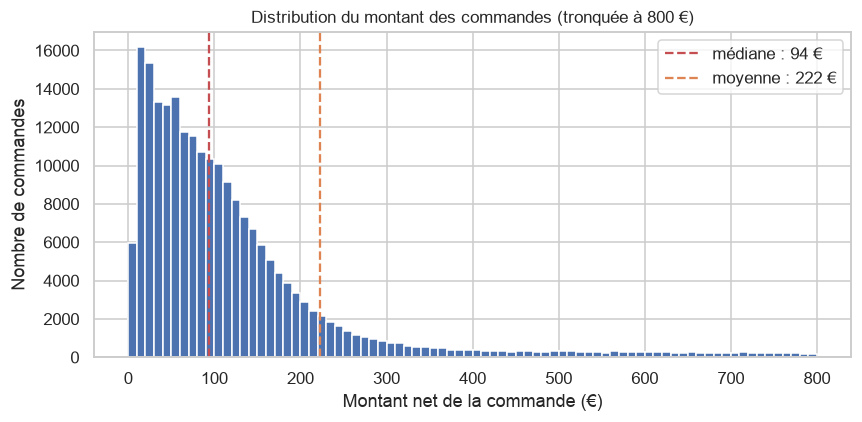

In [26]:
figure, axe = plt.subplots(figsize=(8, 4))
axe.hist(paniers_positifs, bins=80, range=(0, 800), color="#4c72b0")
axe.axvline(paniers_positifs.median(), color="#c44e52", linestyle="--",
            label=f"médiane : {paniers_positifs.median():.0f} €")
axe.axvline(paniers_positifs.mean(), color="#dd8452", linestyle="--",
            label=f"moyenne : {paniers_positifs.mean():.0f} €")
axe.set_title("Distribution du montant des commandes (tronquée à 800 €)")
axe.set_xlabel("Montant net de la commande (€)")
axe.set_ylabel("Nombre de commandes")
axe.legend()
plt.tight_layout()
plt.show()

Distribution très asymétrique, ce qui est la norme sur des montants d'achat. La
médiane est à 94 € et la moyenne à 222 € : l'écart entre les deux vient
entièrement de la queue de droite. Un pour cent des commandes dépasse 2 300 €, et
la plus grosse atteint 43 915 €.

J'ai tronqué le graphique à 800 € parce que sans ça l'axe s'étirerait jusqu'à
44 000 € et écraserait toute la distribution en une seule barre. La troncature
masque un peu plus de 5 % des commandes. C'est acceptable ici puisqu'on cherche
la forme générale, mais il faut le dire.

Conséquence pratique : la moyenne n'est pas un bon repère pour parler du client
type. Si le CMO cale un seuil de livraison gratuite sur un « panier moyen de
222 € », il le place au-dessus de 80 % de ses commandes. La médiane est le bon
chiffre à lui donner.

Ces très gros paniers sont probablement les comptes professionnels repérés à
l'étape 2. On le vérifie en 3.6.

### 3.2 À quelle fréquence achète-t-on

In [27]:
frequence = profil_clients["nb_commandes"]

print(frequence.describe().round(2).to_string())
print()
repartition_frequence = (
    frequence.value_counts().sort_index().head(10).to_frame("nb_clients")
)
repartition_frequence["part_pct"] = (
    repartition_frequence["nb_clients"] / len(frequence) * 100
).round(1)
print(repartition_frequence.to_string())
print()
print("clients à une seule commande   : %.1f %%"
      % ((frequence == 1).mean() * 100))
print("clients à 10 commandes ou plus : %.1f %%"
      % ((frequence >= 10).mean() * 100))

count    49328.00
mean         4.54
std          6.53
min          1.00
25%          1.00
50%          3.00
75%          6.00
max        466.00

              nb_clients  part_pct
nb_commandes                      
1                  14392      29.2
2                   8506      17.2
3                   6229      12.6
4                   4045       8.2
5                   3060       6.2
6                   2388       4.8
7                   2009       4.1
8                   1533       3.1
9                   1273       2.6
10                  1032       2.1

clients à une seule commande   : 29.2 %
clients à 10 commandes ou plus : 11.9 %


29 % des clients n'ont commandé qu'une fois, et la médiane est à 3 commandes. La
distribution décroît régulièrement : chaque commande supplémentaire fait perdre
entre un quart et un tiers de l'effectif.

Le chiffre à retenir pour le CMO est le premier. Près d'un client sur trois n'a
jamais reconverti. C'est déjà une réponse partielle à sa question : ces
14 392 clients n'ont pas les mêmes besoins qu'un client qui commande six fois par
an, et leur envoyer le même message revient à ignorer le seul enjeu qui les
concerne, la deuxième commande.

### 3.3 Concentration du chiffre d'affaires

La loi de Pareto veut que 20 % des clients fassent 80 % du chiffre d'affaires.
C'est une règle empirique, pas une loi : autant vérifier plutôt que la citer.

In [28]:
ca_trie = profil_clients["ca_net"].sort_values(ascending=False)
ca_trie = ca_trie[ca_trie > 0]
part_cumulee_ca = ca_trie.cumsum() / ca_trie.sum()
part_cumulee_clients = np.arange(1, len(ca_trie) + 1) / len(ca_trie)

SEUIL_PARETO = 0.80
nb_clients_80 = int((part_cumulee_ca <= SEUIL_PARETO).sum()) + 1

print("clients générant 80 %% du CA : %d sur %d (%.1f %%)"
      % (nb_clients_80, len(ca_trie), nb_clients_80 / len(ca_trie) * 100))
for part in [0.05, 0.10, 0.20, 0.50]:
    rang = int(len(ca_trie) * part) - 1
    print("  le top %3.0f %% des clients pèse %.1f %% du CA"
          % (part * 100, part_cumulee_ca.iloc[rang] * 100))

clients générant 80 % du CA : 12871 sur 49009 (26.3 %)
  le top   5 % des clients pèse 52.5 % du CA
  le top  10 % des clients pèse 62.4 % du CA
  le top  20 % des clients pèse 74.7 % du CA
  le top  50 % des clients pèse 92.2 % du CA


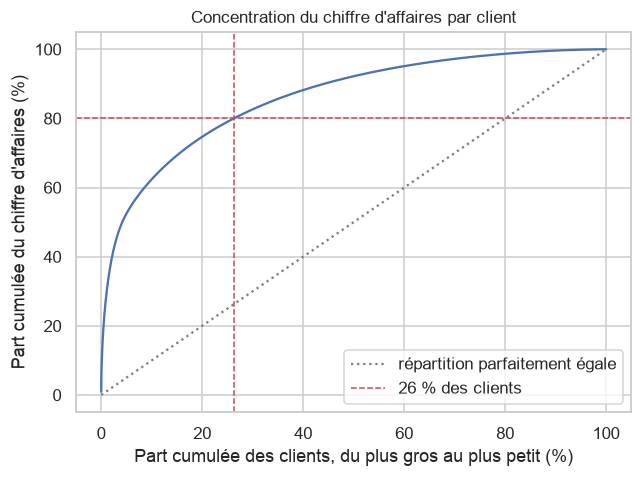

In [29]:
figure, axe = plt.subplots(figsize=(6, 4.5))
axe.plot(part_cumulee_clients * 100, part_cumulee_ca * 100, color="#4c72b0")
axe.plot([0, 100], [0, 100], color="grey", linestyle=":",
         label="répartition parfaitement égale")
axe.axhline(SEUIL_PARETO * 100, color="#c44e52", linestyle="--", linewidth=1)
axe.axvline(nb_clients_80 / len(ca_trie) * 100, color="#c44e52",
            linestyle="--", linewidth=1,
            label=f"{nb_clients_80 / len(ca_trie) * 100:.0f} % des clients")
axe.set_title("Concentration du chiffre d'affaires par client")
axe.set_xlabel("Part cumulée des clients, du plus gros au plus petit (%)")
axe.set_ylabel("Part cumulée du chiffre d'affaires (%)")
axe.legend(loc="lower right")
plt.tight_layout()
plt.show()

Il faut 26 % des clients pour atteindre 80 % du chiffre d'affaires. La
concentration est donc un peu moins forte que ce que dit la règle, mais elle
reste très marquée : le top 10 % pèse à lui seul 62 % du CA.

Pour le CMO, c'est l'argument le plus direct contre l'envoi unique. Un email
adressé à toute la base traite de la même façon les 4 900 clients qui font près
des deux tiers du chiffre et les 24 500 de la moitié basse qui en font 8 %. Le
coût d'un email est le même dans les deux cas, la valeur en jeu n'a rien à voir.

Un point d'honnêteté : cette courbe est calculée sur les clients identifiés. Les
16 % de CA anonymes ne sont attribuables à personne et n'y figurent pas. La
concentration réelle est probablement un peu moins forte que celle-ci, puisqu'une
partie des ventes non rattachées appartient sans doute à de petits clients.

### 3.4 Saisonnalité

C'est ici que le CMO attend le plus : quand faut-il pousser les campagnes.
Commençons par le chiffre d'affaires mensuel brut, en séparant les deux sources
d'export repérées à l'étape 2.

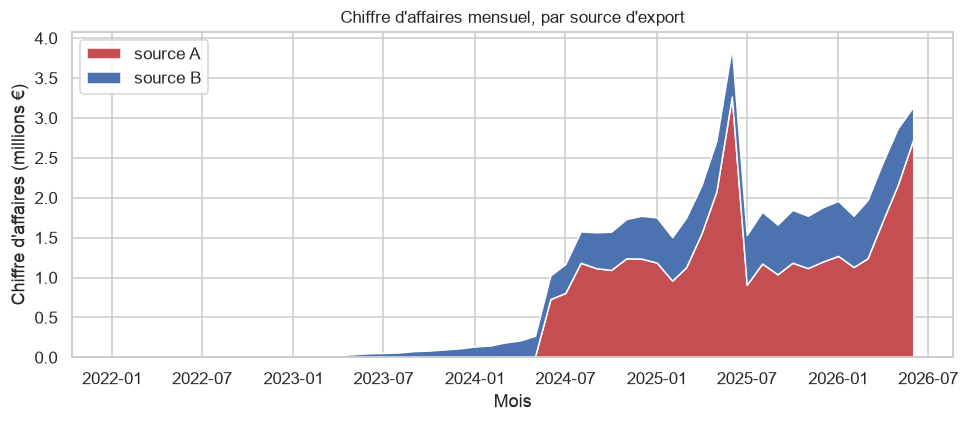

source_export          A         B
mois                              
2024-03-01        1879.0  184382.0
2024-04-01        3827.0  208380.0
2024-05-01       11306.0  258748.0
2024-06-01      730852.0  295842.0
2024-07-01      807272.0  362371.0
2024-08-01     1185562.0  392651.0


In [30]:
ventes_mensuelles = ventes_produit.copy()
ventes_mensuelles["mois"] = (
    ventes_mensuelles["invoice_date"].dt.to_period("M").dt.to_timestamp()
)
ca_par_mois_et_source = ventes_mensuelles.pivot_table(
    index="mois", columns="source_export", values="line_total", aggfunc="sum"
).fillna(0)

figure, axe = plt.subplots(figsize=(9, 4))
axe.stackplot(
    ca_par_mois_et_source.index,
    ca_par_mois_et_source["A"] / 1e6,
    ca_par_mois_et_source["B"] / 1e6,
    labels=["source A", "source B"],
    colors=["#c44e52", "#4c72b0"],
)
axe.set_title("Chiffre d'affaires mensuel, par source d'export")
axe.set_xlabel("Mois")
axe.set_ylabel("Chiffre d'affaires (millions €)")
axe.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(ca_par_mois_et_source.loc["2024-03":"2024-08"].round(0).to_string())

La courbe donne l'impression d'une croissance spectaculaire jusqu'à mi-2024, puis
d'un palier. C'est exactement le récit du CMO. Sauf que le graphique montre d'où
vient la marche : la source A n'existe pas avant mars 2024, elle pèse 11 000 € en
mai 2024 et 731 000 € en juin. Une entreprise ne multiplie pas son chiffre par
65 en un mois. C'est la date à laquelle le second export commence à être
alimenté.

Je ne peux donc pas conclure sur la tendance longue. Ce que je peux dire, c'est
que la période à partir de septembre 2024 est la seule où les deux sources sont
présentes en continu, et c'est la seule sur laquelle une comparaison mensuelle a
du sens. Tout le reste du notebook qui touche au temps se limite à cette fenêtre.

In [31]:
DEBUT_FENETRE_STABLE = "2024-09"  # premier mois où les deux sources coexistent

ca_mensuel = ca_par_mois_et_source.sum(axis=1).loc[DEBUT_FENETRE_STABLE:]
moyenne_mobile_annuelle = ca_mensuel.rolling(12, center=True).mean()
indice_saisonnier = (ca_mensuel / moyenne_mobile_annuelle).dropna()

resume_saisonnier = indice_saisonnier.to_frame("indice")
resume_saisonnier["mois_calendaire"] = resume_saisonnier.index.month
print("indice = CA du mois / moyenne mobile sur 12 mois")
print("un indice de 1,20 signifie 20 % au-dessus du niveau habituel\n")
print(resume_saisonnier.round(2).to_string())

indice = CA du mois / moyenne mobile sur 12 mois
un indice de 1,20 signifie 20 % au-dessus du niveau habituel

            indice  mois_calendaire
mois                               
2025-03-01    0.88                3
2025-04-01    1.08                4
2025-05-01    1.35                5
2025-06-01    1.93                6
2025-07-01    0.76                7
2025-08-01    0.89                8
2025-09-01    0.81                9
2025-10-01    0.89               10
2025-11-01    0.84               11
2025-12-01    0.89               12
2026-01-01    0.95                1


La moyenne mobile centrée sur douze mois donne le niveau « hors saison » de
chaque mois : en divisant le mois réel par cette moyenne, la tendance s'annule et
il ne reste que l'effet calendaire. Douze mois d'historique disparaissent au
passage — six de chaque côté — d'où seulement onze points exploitables.

Le résultat est net : mai et juin sortent très au-dessus (1,35 et 1,93), juillet
et septembre très en dessous (0,76 et 0,81). Décembre est à 0,89, sous la
moyenne. Pour une marque de cosmétiques, un décembre creux est contre-intuitif :
c'est le mois des coffrets cadeaux.

Ce détail me pousse à tester si cette saisonnalité est bien une saisonnalité
commerciale.

In [32]:
fenetre_stable = ventes_mensuelles[
    ventes_mensuelles["mois"] >= DEBUT_FENETRE_STABLE
]

ca_par_mois_calendaire = fenetre_stable.pivot_table(
    index=fenetre_stable["invoice_date"].dt.month,
    columns="category",
    values="line_total",
    aggfunc="sum",
)
indice_par_categorie = ca_par_mois_calendaire.div(
    ca_par_mois_calendaire.mean(axis=0), axis=1
)
indice_par_categorie.index.name = "mois calendaire"

print("indice de saisonnalité, catégorie par catégorie :")
print(indice_par_categorie.round(2).to_string())
print("\nécart entre la catégorie la plus et la moins saisonnière, par mois :")
print((indice_par_categorie.max(axis=1)
       - indice_par_categorie.min(axis=1)).round(2).to_string())

ca_mois_calendaire_source = fenetre_stable.pivot_table(
    index=fenetre_stable["invoice_date"].dt.month,
    columns="source_export",
    values="line_total",
    aggfunc="sum",
)
indice_par_source = ca_mois_calendaire_source.div(
    ca_mois_calendaire_source.mean(axis=0), axis=1
)
indice_par_source.index.name = "mois calendaire"
print("\nle même indice, source par source :")
print(indice_par_source.round(2).to_string())

indice de saisonnalité, catégorie par catégorie :
category         Accessoire  Bain  Cheveux  Coffret  Corps  Visage
mois calendaire                                                   
1                      1.01  0.99     0.99     1.02   0.96    0.98
2                      0.90  0.89     0.87     0.87   0.86    0.87
3                      1.01  1.01     0.98     0.99   0.98    0.99
4                      1.24  1.22     1.21     1.20   1.25    1.23
5                      1.45  1.48     1.51     1.45   1.54    1.48
6                      1.80  1.85     1.86     1.80   1.92    1.91
7                      0.42  0.40     0.41     0.39   0.41    0.41
8                      0.50  0.49     0.50     0.47   0.48    0.49
9                      0.86  0.84     0.86     0.87   0.86    0.86
10                     0.89  0.92     0.92     0.95   0.89    0.90
11                     0.92  0.96     0.93     0.97   0.91    0.93
12                     1.02  0.96     0.95     1.03   0.94    0.96

écart entre

Les six catégories ont exactement le même profil mensuel. L'écart entre la
catégorie la plus marquée et la moins marquée ne dépasse jamais 0,12 sur un
indice qui varie de 0,39 à 1,92.

Ce n'est pas ce que produit une saisonnalité commerciale. Si le pic de juin était
un vrai comportement d'achat, les huiles corps et les produits de bain
monteraient plus que les soins visage, et les coffrets décolleraient en décembre.
Ici tout monte et tout descend ensemble, dans les mêmes proportions : c'est un
effet de volume qui s'applique uniformément au catalogue.

Le découpage par source affine le diagnostic, et il oblige à distinguer deux
choses que j'avais tendance à mettre dans le même sac. Le pic de mai-juin ne
vient que de la source A : 2,27 en juin, contre 0,92 pour la source B, qui ne
connaît aucun pic de printemps. Celui-là est très probablement un artefact.
Le creux de juillet-août, lui, se retrouve dans les deux sources — 0,34 et 0,56
en juillet — et c'est le seul motif que les deux exports racontent ensemble.

Ce que je retiens, donc. Le seul effet calendaire que je peux défendre est le
ralentissement d'été, cohérent avec ce qu'on observe sur beaucoup de marques
grand public en France. Le pic de printemps ne repose que sur une source et ne se
différencie pas par catégorie : je ne recommanderai pas de caler un plan média
dessus. La question à poser au CMO est simple, et elle vaut mieux qu'une
conclusion inventée : est-ce que mai-juin est vraiment votre haute saison ?

### 3.5 Géographie

L'étape 1 a montré que la France pèse 91 % des clients. Reste à savoir si les
autres pays se comportent différemment, ce qui justifierait de les traiter à
part.

In [33]:
NB_PAYS_AFFICHES = 8

analyse_pays = profil_clients.groupby("pays").agg(
    nb_clients=("ca_net", "size"),
    ca_total=("ca_net", "sum"),
    panier_median=("panier_moyen", "median"),
    commandes_medianes=("nb_commandes", "median"),
)
analyse_pays["part_clients_pct"] = (
    analyse_pays["nb_clients"] / analyse_pays["nb_clients"].sum() * 100
).round(1)
analyse_pays["part_ca_pct"] = (
    analyse_pays["ca_total"] / analyse_pays["ca_total"].sum() * 100
).round(1)

print(analyse_pays.sort_values("nb_clients", ascending=False)
      .head(NB_PAYS_AFFICHES)
      [["nb_clients", "part_clients_pct", "part_ca_pct",
        "panier_median", "commandes_medianes"]]
      .round(1).to_string())

                nb_clients  part_clients_pct  part_ca_pct  panier_median  commandes_medianes
pays                                                                                        
France               45001              91.3         91.0           96.5                 3.0
Germany                905               1.8          1.9          102.4                 3.0
United Kingdom         744               1.5          1.6           97.3                 3.0
Spain                  285               0.6          0.4           97.4                 2.0
Portugal               207               0.4          0.3           98.3                 2.0
Belgium                201               0.4          0.4           98.4                 4.0
Switzerland            183               0.4          0.4          101.1                 3.0
Netherlands            162               0.3          0.5          105.5                 2.0


Pas de graphique ici : une barre à 91 % et huit barres écrasées contre l'axe
n'apprendraient rien que le tableau ne dise mieux.

Deux lectures. D'abord la France concentre 91 % des clients et 91 % du chiffre :
sa domination n'est pas un artefact du nombre, elle achète comme les autres.
Ensuite, et c'est plus intéressant, les autres pays ne se distinguent pas. Le
panier médian tient dans une fourchette de 96 à 106 € partout, et la fréquence
médiane entre 2 et 4 commandes. Aucun marché ne sort du lot.

Il faut être clair sur ce que ça vaut. Avec 905 clients allemands et 744
britanniques, on n'a pas la matière pour affirmer qu'il n'existe aucune
différence, seulement pour dire qu'on n'en voit pas. Les pays sous 300 clients
ne devraient pas servir de base à une décision du tout.

**Ce biais est à retenir pour la suite du cours.** Les segments construits demain
décriront le comportement du client français, parce que neuf clients sur dix le
sont. Les appliquer tels quels à l'Allemagne ou au Royaume-Uni serait une
extrapolation, et il faudra le dire en présentation finale.

### 3.6 Relations entre variables

Trois questions : est-ce que les clients récents dépensent plus, est-ce que les
clients fréquents ont un panier plus gros, et est-ce que des groupes se dessinent
sans qu'on ait rien modélisé.

In [34]:
clients_avec_recence = profil_clients.dropna(subset=["recence_jours"])

correlation_lineaire = clients_avec_recence["recence_jours"].corr(
    clients_avec_recence["ca_net"]
)
correlation_rangs = (
    clients_avec_recence["recence_jours"].rank()
    .corr(clients_avec_recence["ca_net"].rank())
)
print("récence et montant dépensé")
print("  corrélation de Pearson (linéaire)  : %.3f" % correlation_lineaire)
print("  corrélation sur les rangs (monotone) : %.3f" % correlation_rangs)

quintiles_recence = pd.qcut(
    clients_avec_recence["recence_jours"], 5,
    labels=["très récent", "récent", "moyen", "ancien", "très ancien"],
)
resume_recence = clients_avec_recence.groupby(
    quintiles_recence, observed=True
).agg(
    nb_clients=("ca_net", "size"),
    recence_mediane=("recence_jours", "median"),
    ca_median=("ca_net", "median"),
    commandes_medianes=("nb_commandes", "median"),
    panier_median=("panier_moyen", "median"),
).round(1)
print()
print(resume_recence.to_string())

récence et montant dépensé
  corrélation de Pearson (linéaire)  : -0.107
  corrélation sur les rangs (monotone) : -0.408

               nb_clients  recence_mediane  ca_median  commandes_medianes  panier_median
recence_jours                                                                           
très récent          9970              9.0      596.7                 6.0           98.1
récent               9767             37.0      433.6                 4.0           98.0
moyen                9896            106.0      333.4                 3.0           95.9
ancien               9865            320.0      208.5                 2.0           95.8
très ancien          9807            529.0      138.7                 1.0           93.8


Les deux mesures ne donnent pas du tout le même résultat. La corrélation de
Pearson vaut -0,11, ce qui donnerait envie de conclure qu'il n'y a pas de lien.
La corrélation sur les rangs vaut -0,41, ce qui est un lien net.

Les deux ne mesurent pas la même chose. Pearson cherche une droite ; sur des
montants aussi dispersés, quelques clients à plusieurs centaines de milliers
d'euros suffisent à la noyer. La corrélation sur les rangs se contente de
demander si le classement des clients par récence suit leur classement par
dépense, sans supposer de forme particulière.

Les quintiles montrent qui a raison : le CA médian passe de 597 € chez les
clients les plus récents à 139 € chez les plus anciens, et décroît à chaque
palier. La relation existe, elle est simplement courbe et pas droite.

Un détail qui compte pour demain : ce n'est pas le panier qui baisse — il reste
autour de 95 € dans tous les quintiles — c'est le nombre de commandes, qui tombe
de 6 à 1. La récence ne mesure pas une perte de pouvoir d'achat, elle mesure une
sortie de la relation.

In [35]:
correlation_frequence_panier = (
    profil_clients["nb_commandes"].rank()
    .corr(profil_clients["panier_moyen"].rank())
)
correlation_frequence_ca = (
    profil_clients["nb_commandes"].rank()
    .corr(profil_clients["ca_net"].rank())
)
print("fréquence et panier moyen : %.3f" % correlation_frequence_panier)
print("fréquence et CA total     : %.3f" % correlation_frequence_ca)

BORNES_FREQUENCE = [0, 1, 2, 4, 9, 19, 10_000]
tranches_frequence = pd.cut(
    profil_clients["nb_commandes"], BORNES_FREQUENCE,
    labels=["1", "2", "3-4", "5-9", "10-19", "20 et +"],
)
resume_frequence = profil_clients.groupby(
    tranches_frequence, observed=True
).agg(
    nb_clients=("panier_moyen", "size"),
    panier_median=("panier_moyen", "median"),
    ca_median=("ca_net", "median"),
).round(1)
print()
print(resume_frequence.to_string())

fréquence et panier moyen : 0.122
fréquence et CA total     : 0.814

              nb_clients  panier_median  ca_median
nb_commandes                                      
1                  14392           88.9       88.9
2                   8506           95.2      190.5
3-4                10274           96.0      323.9
5-9                10263           97.7      637.1
10-19               5312          100.3     1288.1
20 et +              581          334.4    10165.3


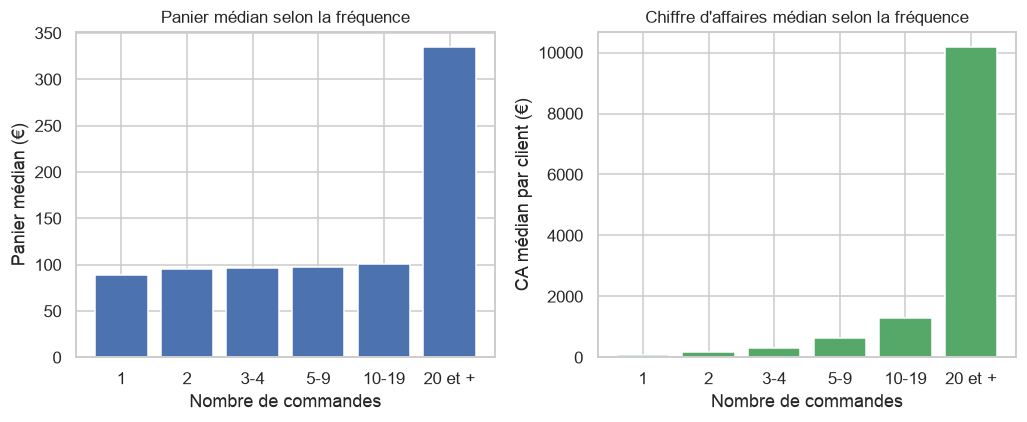

In [36]:
tableau_frequence = profil_clients.groupby(
    tranches_frequence, observed=True
)[["panier_moyen", "ca_net"]].median()

figure, (axe_gauche, axe_droite) = plt.subplots(1, 2, figsize=(9.5, 4))

axe_gauche.bar(tableau_frequence.index.astype(str),
               tableau_frequence["panier_moyen"], color="#4c72b0")
axe_gauche.set_title("Panier médian selon la fréquence")
axe_gauche.set_xlabel("Nombre de commandes")
axe_gauche.set_ylabel("Panier médian (€)")

axe_droite.bar(tableau_frequence.index.astype(str),
               tableau_frequence["ca_net"], color="#55a868")
axe_droite.set_title("Chiffre d'affaires médian selon la fréquence")
axe_droite.set_xlabel("Nombre de commandes")
axe_droite.set_ylabel("CA médian par client (€)")

plt.tight_layout()
plt.show()

Réponse à la question : non, les clients fréquents ne dépensent pas plus par
commande. La corrélation sur les rangs est de 0,12, et le panier médian passe de
89 € chez les clients à une commande à 100 € chez ceux à dix ou vingt. Onze euros
d'écart pour dix fois plus de commandes.

Le graphique de droite raconte l'inverse : le CA médian par client passe de 89 €
à 1 288 €, et la corrélation entre fréquence et CA total est de 0,81. Autrement
dit, **la valeur d'un client se construit entièrement par la répétition, pas par
la taille du panier.** C'est une orientation concrète : les euros sont dans le
déclenchement de la commande suivante, pas dans l'augmentation du montant.

Une exception saute aux yeux. La tranche des 20 commandes et plus décroche
complètement : 581 clients, panier médian de
334 € au lieu de 100, CA médian de 10 165 € au lieu de 1 288. Ce groupe n'est pas
le prolongement de la courbe, c'est autre chose — les comptes professionnels
marqués `profil_atypique` à l'étape 2. Un segment se voit donc à l'œil nu avant
toute modélisation, et il faudra vérifier demain que l'algorithme le retrouve.

### 3.7 Les catégories de produits

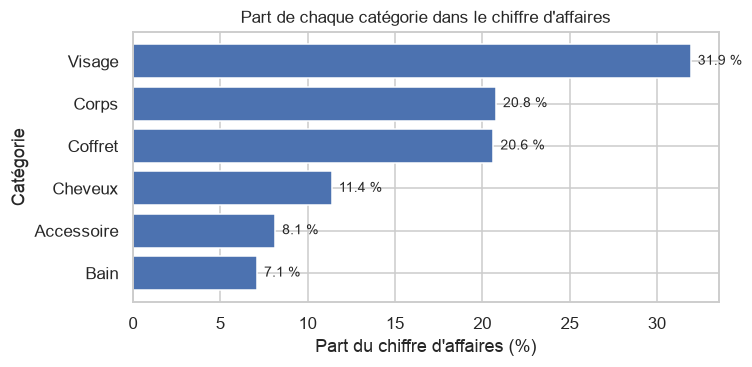

                    ca  part_pct
category                        
Visage      16151610.0      31.9
Corps       10510770.0      20.8
Coffret     10436446.0      20.6
Cheveux      5755402.0      11.4
Accessoire   4115835.0       8.1
Bain         3592667.0       7.1


In [37]:
ca_par_categorie = (
    ventes_produit.groupby("category")["line_total"].sum()
    .sort_values(ascending=False)
)
part_categorie = ca_par_categorie / ca_par_categorie.sum() * 100

figure, axe = plt.subplots(figsize=(7, 3.5))
axe.barh(part_categorie.index[::-1], part_categorie.values[::-1],
         color="#4c72b0")
axe.set_title("Part de chaque catégorie dans le chiffre d'affaires")
axe.set_xlabel("Part du chiffre d'affaires (%)")
axe.set_ylabel("Catégorie")
for position, valeur in enumerate(part_categorie.values[::-1]):
    axe.text(valeur + 0.4, position, f"{valeur:.1f} %",
             va="center", fontsize=9)
plt.tight_layout()
plt.show()

print(pd.DataFrame({
    "ca": ca_par_categorie.round(0),
    "part_pct": part_categorie.round(1),
}).to_string())

Aucune catégorie n'écrase les autres, mais la répartition n'est pas plate non
plus. Le soin visage fait un tiers du chiffre, et avec le corps et les coffrets on
atteint 73 %. Le bain et les accessoires restent sous 10 % chacun.

Les coffrets méritent un mot : 20,6 % du chiffre, presque à égalité avec les
soins corps, alors qu'on les achète en général pour une occasion précise, un
cadeau ou une découverte. Ça recoupe le doute de la partie 3.4 : si les coffrets
pèsent un cinquième du CA sans montrer le moindre pic en décembre, quelque chose
ne colle pas dans la dimension temporelle du fichier.

Ce tableau servira de comparaison demain. Si un segment RFM affiche 45 % de son
chiffre sur une catégorie qui n'en pèse que 20 % globalement, c'est une affinité
produit exploitable pour la personnalisation.

### 3.8 Les données déclaratives

Un mot de définition avant les chiffres, parce que la distinction porte toute
l'analyse.

Une donnée **first-party** est observée : la marque la collecte en regardant ce
que le client fait. Les dates de commande, les montants, les produits achetés
sont du first-party. Le client n'a rien à faire pour qu'elle existe, donc elle est
complète par construction.

Une donnée **zero-party** est déclarée : le client la donne volontairement, en
répondant à un quiz de diagnostic de peau, en remplissant ses préférences dans
son compte. Elle est plus riche — elle dit une intention, pas seulement un
comportement — mais elle n'existe que si quelqu'un a pris le temps de répondre.
D'où un taux de remplissage structurellement partiel, là où le first-party est à
100 %. Ce n'est pas un défaut de qualité, c'est la nature de la donnée.

Dans `customers.csv`, les quatre colonnes déclaratives sont `declared_preference`,
`age_bracket`, `life_stage` et `urban_density`.

In [38]:
CHAMPS_DECLARATIFS = [
    "declared_preference", "age_bracket", "life_stage", "urban_density",
]

taux_remplissage = (
    df_customers_clean[CHAMPS_DECLARATIFS].notna().mean() * 100
).round(1)
print("taux de remplissage (%) :")
print(taux_remplissage.sort_values(ascending=False).to_string())

nb_champs_remplis = df_customers_clean[CHAMPS_DECLARATIFS].notna().sum(axis=1)
print("\nnombre de champs renseignés par client :")
print(nb_champs_remplis.value_counts().sort_index().to_string())
print("\nau moins un champ : %.1f %%" % ((nb_champs_remplis > 0).mean() * 100))
print("les quatre champs : %.1f %%" % ((nb_champs_remplis == 4).mean() * 100))

taux de remplissage (%) :
age_bracket            42.7
declared_preference    38.1
life_stage             22.5
urban_density          19.8

nombre de champs renseignés par client :
0    11053
1    21057
2    14039
3     3786
4      360

au moins un champ : 78.0 %
les quatre champs : 0.7 %


In [39]:
tranches_commandes = pd.cut(
    df_customers_clean["n_orders"], [0, 1, 2, 4, 9, 10_000],
    labels=["1", "2", "3-4", "5-9", "10 et +"],
)
print("champs déclaratifs renseignés, selon l'activité du client :")
print(nb_champs_remplis.groupby(tranches_commandes, observed=True)
      .mean().round(2).to_string())

print("\nvaleurs déclarées pour la préférence produit :")
print(df_customers_clean["declared_preference"].value_counts().to_string())

champs déclaratifs renseignés, selon l'activité du client :
n_orders
1          1.24
2          1.22
3-4        1.24
5-9        1.22
10 et +    1.23

valeurs déclarées pour la préférence produit :
declared_preference
Peau sensible         2815
Anti-âge              2768
Anti-imperfections    2764
Recherche vegan       2749
Peau mixte            2715
Peau sèche            2694
Sans parfum           2682


Les taux vont de 19,8 % pour la densité urbaine à 42,7 % pour la tranche d'âge.
78 % des clients ont renseigné au moins un champ, mais 0,7 % seulement ont
répondu aux quatre. C'est cohérent avec ce qu'on attend d'une donnée zero-party :
les gens répondent à ce qui leur coûte peu et abandonnent le reste. On retrouve
d'ailleurs la hiérarchie habituelle — l'âge se donne facilement, la situation de
vie et le lieu d'habitation beaucoup moins.

Deux choses détonnent en revanche.

Le remplissage ne dépend pas de l'activité du client. Un client à une seule
commande a renseigné 1,24 champ en moyenne, un client à dix commandes ou plus
1,23. C'est contraire à tout ce qu'on attend : plus un client est engagé, plus il
accepte normalement de se déclarer. Ici la relation est plate, ce qui suggère que
ces champs ont été collectés en une fois, probablement à l'inscription, et jamais
enrichis depuis.

Et les sept préférences déclarées se répartissent de façon presque parfaitement
égale, entre 2 682 et 2 815 clients chacune. Une vraie base déclarative n'est
jamais aussi équilibrée : sur une marque de cosmétiques, « peau sensible » et
« anti-âge » ne recrutent pas le même nombre de personnes. Cette uniformité
ressemble davantage à une attribution aléatoire qu'à un choix des clients.

Conséquence pour le Jour 2 : je n'utiliserai pas `declared_preference` comme
variable de segmentation. Segmenter sur un champ vide à 62 % et dont les valeurs
semblent tirées au sort produirait des groupes qui n'ont pas de sens. Ces colonnes
restent dans le dataset, elles pourront servir à décrire les segments après coup,
pas à les construire.

## 4. Cinq hypothèses à tester demain

L'exploration a produit des constats. Une hypothèse, c'est autre chose : c'est un
pari sur ce que ces constats veulent dire, formulé de façon à pouvoir être
démenti. Les cinq qui suivent sont toutes rattachées à un chiffre du notebook, et
toutes vérifiables avec la segmentation du Jour 2.

J'ai écrit à côté de chacune ce qui l'invaliderait. C'est la partie qui m'a le
plus coûté : il est facile d'écrire une hypothèse qu'aucun résultat ne peut
contredire, et elle ne sert alors à rien.

### Hypothèse 1 — les clients à une seule commande ne sont pas de mauvais clients

> Je suppose que les 14 392 clients à commande unique (29,2 % de la base, partie
> 3.2), dont le panier médian de 89 € est à peine inférieur aux 100 € des clients
> à dix commandes et plus (partie 3.6), n'ont pas un problème de budget mais
> d'absence de raison de revenir, ce qui suggère de leur adresser une séquence de
> deuxième commande distincte du programme de fidélité.

Le raisonnement tient au fait que le panier ne bouge pas. Si ces clients avaient
acheté moins cher que les autres, on pourrait penser à un essai prudent ou à une
contrainte de budget. Ils dépensent presque la même chose que les clients
fidèles, une seule fois. L'écart de valeur ne vient donc pas de ce qu'ils sont
capables de dépenser.

Ce qui l'invaliderait : si le Jour 2 montre que ces clients se répartissent dans
tous les segments au lieu de former un groupe cohérent, ou si leur date d'achat
unique se concentre sur les derniers mois — auquel cas ce ne seraient pas des
clients perdus mais des clients récents qui n'ont pas encore eu le temps de
recommander.

### Hypothèse 2 — la valeur se gagne sur la fréquence, pas sur le panier

> Je suppose que la corrélation de 0,81 entre nombre de commandes et chiffre
> d'affaires par client, contre 0,12 entre nombre de commandes et panier moyen
> (partie 3.6), implique que la valeur d'un client se construit par la répétition
> et non par le montant de chaque achat, ce qui suggère de déplacer l'effort des
> mécaniques d'augmentation du panier vers celles qui déclenchent la commande
> suivante.

C'est celle qui engage le plus de budget des cinq, parce qu'elle porte sur la
répartition des dépenses marketing. Concrètement, elle dit qu'une relance à quarante-cinq
jours rapporte plus qu'une offre « + 20 € pour la livraison offerte ».

Ce qui l'invaliderait : si les segments à forte valeur du Jour 2 se distinguent
d'abord par leur montant moyen et non par leur nombre de commandes. À surveiller
aussi, un effet mécanique — un client qui commande plus a forcément un CA cumulé
plus élevé. La comparaison utile sera donc à fréquence égale : parmi les clients
à cinq commandes, l'écart de valeur vient-il du panier ou d'autre chose.

### Hypothèse 3 — le décrochage se voit avant qu'il soit consommé

> Je suppose que la baisse du CA médian de 597 € à 139 € entre le quintile de
> récence le plus récent et le plus ancien, portée entièrement par le nombre de
> commandes qui passe de 6 à 1 alors que le panier reste autour de 95 €
> (partie 3.6), traduit une sortie progressive de la relation et non une perte de
> pouvoir d'achat, ce qui suggère de déclencher une relance à un seuil de récence
> fixé plutôt que d'attendre l'inactivité déclarée.

Le quintile intermédiaire donne une piste de seuil : récence médiane de 106 jours
et 3 commandes. C'est le dernier palier où les clients ont encore un historique
d'achats répétés. Au-delà, la médiane tombe à 2 puis à 1 commande.

Ce qui l'invaliderait : si le RFM montre que les clients anciens et les clients
récents ont des profils d'achat comparables par ailleurs, la récence ne serait
qu'un effet d'ancienneté de la base et pas un signal de désengagement.

### Hypothèse 4 — quelques centaines de comptes ne sont pas des consommateurs

> Je suppose que les 581 clients à vingt commandes ou plus, dont le panier médian
> de 334 € et le CA médian de 10 165 € sortent complètement de la progression
> observée sur toutes les autres tranches (partie 3.6), sont des revendeurs ou
> des comptes professionnels et non des particuliers, ce qui suggère de les
> exclure des campagnes grand public et de leur affecter un traitement dédié.

Ce n'est pas une extrapolation : la rupture est nette. Sur les cinq premières
tranches le panier médian monte de 89 € à 100 €, puis il triple d'un coup. Un
particulier n'achète pas trois cent trente euros de cosmétiques à chaque
commande, vingt fois par an.

L'enjeu dépasse le ciblage. Ces comptes tirent les moyennes de toute la base :
c'est en partie à cause d'eux que le panier moyen est à 222 € quand la médiane
est à 94 € (partie 3.1). Tant qu'ils y sont, aucune moyenne calculée sur la base
entière ne décrit un client réel.

Ce qui l'invaliderait : si le clustering du Jour 2 ne les isole pas, ou s'il les
mélange avec des particuliers très fidèles. Le flag `profil_atypique` posé à
l'étape 2 permettra de vérifier directement où ils tombent.

### Hypothèse 5 — la collecte déclarative s'est arrêtée après l'inscription

> Je suppose que le nombre moyen de champs déclaratifs renseignés, identique à
> 1,23 pour un client à dix commandes et à 1,24 pour un client à commande unique
> (partie 3.8), implique que ces données sont recueillies une seule fois à
> l'inscription et jamais enrichies, ce qui suggère d'installer des points de
> collecte après l'achat plutôt que d'exploiter en l'état des champs vides aux
> trois quarts.

Le comportement attendu serait inverse : plus un client commande, plus il a
d'occasions de se déclarer et plus il a de raisons de le faire. La courbe plate
n'est pas un résultat neutre, c'est le signe qu'aucun dispositif ne relance la
collecte après la création du compte.

Ce qui l'invaliderait : si les clients les plus engagés du Jour 2 se révèlent
mieux renseignés que la moyenne une fois qu'on raisonne à ancienneté comparable.
Un client inscrit il y a trois ans a pu remplir son profil à une époque où le
formulaire était différent.

Une réserve à porter : la répartition presque parfaitement égale des sept
préférences déclarées, entre 2 682 et 2 815 clients (partie 3.8), fait douter de
la fiabilité de ce champ. Si ces valeurs sont attribuées au hasard, l'hypothèse
porte sur un artefact. C'est la plus fragile des cinq et je la présente comme
telle.

## 5. Export du dataset nettoyé

Deux fichiers, au format Parquet. Ce format stocke les types avec les données :
en rechargeant le fichier demain, `invoice_date` sera encore une date et les
indicateurs encore des booléens, sans avoir à repasser par `parse_dates` ni à
espérer que pandas devine juste. Il est aussi compressé par colonne, ce qui
compte sur 1,6 million de lignes.

J'exporte en plus la table client en CSV, parce qu'elle est petite et que ça
permet de l'ouvrir dans un tableur pour vérifier un client à la main. Je ne le
fais pas pour les transactions : le CSV correspondant dépasserait 200 Mo.

In [40]:
DOSSIER_TRAITE.mkdir(parents=True, exist_ok=True)

chemin_transactions = DOSSIER_TRAITE / "transactions_clean.parquet"
chemin_clients = DOSSIER_TRAITE / "customers_clean.parquet"

df_transactions_clean.to_parquet(chemin_transactions, index=False)
df_customers_clean.to_parquet(chemin_clients, index=False)
df_customers_clean.to_csv(DOSSIER_TRAITE / "customers_clean.csv", index=False)

for chemin in sorted(DOSSIER_TRAITE.iterdir()):
    print("%-32s %8.1f Mo" % (chemin.name, chemin.stat().st_size / 1e6))

customers_clean.csv                   5.0 Mo
customers_clean.parquet               1.3 Mo
transactions_clean.parquet           27.2 Mo


In [41]:
relecture = pd.read_parquet(chemin_transactions)

print("lignes relues :", len(relecture))
print("types préservés :")
print(relecture.dtypes.to_string())
print("\nidentique à la table en mémoire :",
      relecture.equals(df_transactions_clean.reset_index(drop=True)))

lignes relues : 1612988
types préservés :
invoice_id                      str
client_rattache               Int64
product_code                    str
product_name                    str
category                        str
quantity                      int64
unit_price                  float64
line_total                  float64
invoice_date         datetime64[us]
country                         str
source_export                   str
client_identifie               bool
est_retour                     bool
est_avoir                      bool
ligne_gratuite                 bool
est_ligne_produit              bool

identique à la table en mémoire : True


### Ce qu'il faut savoir avant de réutiliser ces fichiers

Le dataset n'est pas filtré. Toutes les lignes sont là, y compris les retours,
les lignes gratuites, les frais de port et les ventes sans client. Les
indicateurs servent à choisir le périmètre au moment de l'analyse, et c'est
volontaire : chaque question appelle un périmètre différent.

En pratique, pour le RFM de demain :

```
ventes = df[df["est_ligne_produit"] & df["client_identifie"]]
rfm = ventes.groupby("client_rattache").agg(
    montant=("line_total", "sum"),        # somme signée, retours déduits
    frequence=("invoice_id", "nunique"),
    dernier_achat=("invoice_date", "max"),
)
```

Trois pièges à ne pas retomber dedans :

Le montant doit être une somme signée. Prendre la valeur absolue reviendrait à
compter un retour comme un achat.

Le montant de valeur client se calcule depuis les transactions, pas depuis
`total_spent`. Les deux fichiers ne se réconcilient pas — écart d'un facteur 3,
partie 2.6 — et seule la version recalculée est traçable.

La récence se mesure par rapport au 30/06/2026, date de la dernière transaction
du fichier, pas par rapport à la date du jour. Sinon l'ancienneté de l'extraction
vient s'ajouter à la récence de tous les clients.

## 6. Limites à reporter en présentation finale

Cinq points qui ne sont pas des défauts de méthode mais des propriétés des
données, et qui devront être dits au CMO plutôt que découverts par lui.

**Le fichier réunit deux exports aux populations disjointes.** 7 399 clients d'un
côté, 42 004 de l'autre, un seul en commun. Un segment composé à 95 % d'une seule
source sera un artefact avant d'être un comportement.

**La base est française à 91 %.** Les segments décriront le client français. Les
appliquer à l'Allemagne ou au Royaume-Uni, où l'on compte 905 et 744 clients,
serait une extrapolation.

**16 % du chiffre d'affaires n'est rattaché à aucun client.** Les analyses par
client portent sur 84 % des ventes. La concentration mesurée en partie 3.3 est
probablement un peu surestimée pour cette raison.

**La tendance du chiffre d'affaires n'est pas interprétable.** La courbe montre
une croissance qui est en réalité la montée en charge du second export. Le seul
motif temporel défendable est le ralentissement estival.

**Les données déclaratives ne sont pas exploitables pour segmenter.** Vides à 62 %
au mieux, et distribuées de façon suspecte. Elles serviront à décrire les
segments, pas à les construire.